## 0. Описание задачи  
**Датасет:** Intermediate Core ML Assignment Dataset (50 000 строк, 18 колонок).  
**Задача:** Бинарная классификация. Предсказать, уйдёт ли клиент (`churn` = 1) или останется (`churn` = 0).  
**Бизнес-смысл:** Компании дешевле удержать клиента, чем привлечь нового. Заранее выявляя уходящих клиентов, можно предложить им скидку или бонус.  

**Особенности данных:**
- 16 признаков (8 числовых, 8 категориальных).  
- Целевая переменная `churn` имеет сильный дисбаланс (~10% ушедших, 90% оставшихся).  
- Есть пропуски в данных (0.44%).

In [1]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

#1. Чтение данных
df = pd.read_csv("intermediate_coreml_assignment_dataset.csv")
print("Размер данных:", df.shape)
df.head()

Размер данных: (50000, 18)


,customer_id,age,tenure_months,income,credit_score,monthly_charges,support_tickets,avg_session_time,late_payments,gender,city_tier,plan_type,payment_method,device_type,has_international,is_student,target_reg,churn
0,200001,51,6,23039.19,718.0,1065.30,0,28.36,0,Female,Tier1,Basic,UPI,Android,No,No,44030.77,0
1,200002,46,116,54173.02,491.0,1035.67,1,15.75,0,Male,Tier2,Basic,Card,Android,No,No,138673.42,0
2,200003,20,112,37130.61,623.0,897.50,1,15.15,0,Female,Tier1,Standard,Card,Android,No,No,159250.49,0
3,200004,18,53,39873.95,850.0,1095.42,3,26.83,0,Male,Tier1,Standard,UPI,Android,No,No,109410.17,1
4,200005,22,60,39591.09,779.0,1422.29,0,18.83,0,Male,Tier2,Premium,Card,Android,No,No,91008.23,0


In [2]:
#2. Разбиение данных на обучающую и тестовую выборки
# customer_id, churn и target_reg не являются признаками
X = df.drop(columns=['customer_id', 'churn', 'target_reg'])
y = df['churn']

# Разбиваем 70/30 со стратификацией
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Доля churn в train: {y_train.mean():.3f}, в test: {y_test.mean():.3f}")

Train: (35000, 15), Test: (15000, 15)
Доля churn в train: 0.101, в test: 0.101


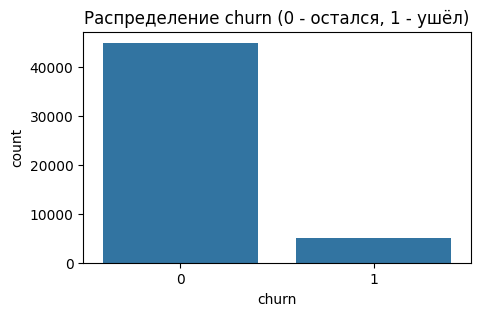

churn
0    0.89854
1    0.10146
Name: proportion, dtype: float64


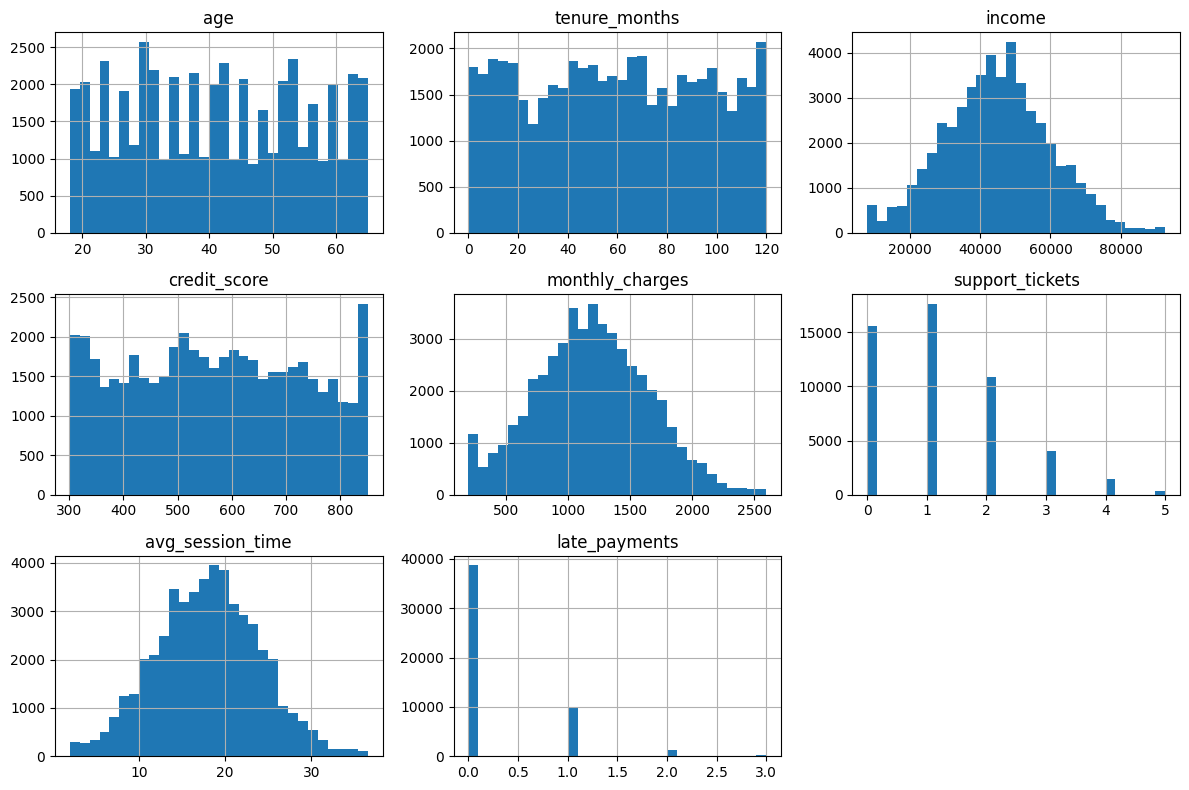

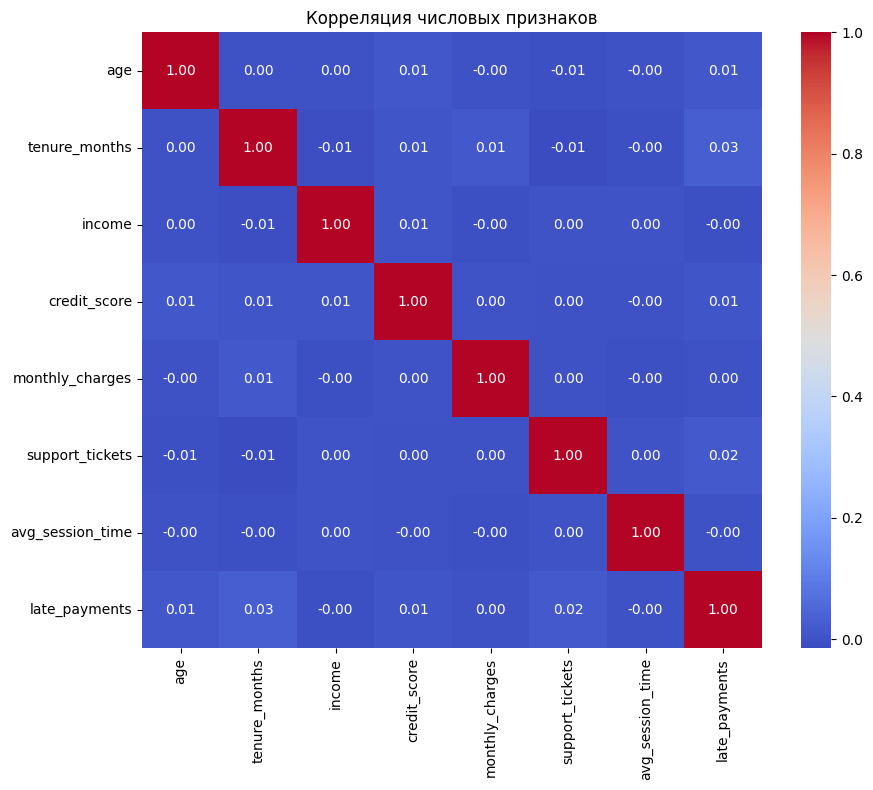

In [3]:
#3. Визуализация данных и вычисление основных характеристик
# Дисбаланс классов
plt.figure(figsize=(5,3))
sns.countplot(x=y)
plt.title("Распределение churn (0 - остался, 1 - ушёл)")
plt.show()
print(y.value_counts(normalize=True))

# Числовые признаки
num_cols = X.select_dtypes(include=np.number).columns
X[num_cols].hist(figsize=(12,8), bins=30)
plt.tight_layout()
plt.show()

# Корреляционная матрица
plt.figure(figsize=(10,8))
sns.heatmap(X[num_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Корреляция числовых признаков")
plt.show()

In [4]:
#4. Выбросы
# Функция для обрезки выбросов (train)
def clip_outliers(df, cols):
    df = df.copy()
    for col in cols:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        df[col] = df[col].clip(lower, upper)
    return df

# Применяем только к непрерывным числовым признакам
continuous_cols = ['income', 'credit_score', 'monthly_charges', 'avg_session_time']
X_train = clip_outliers(X_train, continuous_cols)

In [5]:
# Разделяем признаки на числовые и категориальные
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(include='object').columns.tolist()

print("Числовые:", numeric_features)
print("Категориальные:", categorical_features)

# Числовой пайплайн
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')), #5. Обработка пропущенных значений
    ('scaler', StandardScaler()) #7. Нормализация
])

# Категориальный пайплайн
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')), #5. Обработка пропущенных значений
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)) #6. Обработка категориальных признаков
])

# Объединение
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

Числовые: ['age', 'tenure_months', 'income', 'credit_score', 'monthly_charges', 'support_tickets', 'avg_session_time', 'late_payments']
Категориальные: ['gender', 'city_tier', 'plan_type', 'payment_method', 'device_type', 'has_international', 'is_student']


In [6]:
#8. Запуск классификатора (метод KNN)
from sklearn.neighbors import KNeighborsClassifier

# Создание пайплайна
knn_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier())
])

In [7]:
#9. Выбор оптимального значения гиперпараметра k
from sklearn.model_selection import GridSearchCV

# Проверяем k от 1 до 21)
param_grid = {'classifier__n_neighbors': range(1, 22, 2)}

# Ищем лучшее k по F1-мере (для класса 1, так как у нас дисбаланс)
grid_search = GridSearchCV(
    knn_pipeline, param_grid, cv=5, scoring='f1', n_jobs=-1
)

# Обучение (перебор всех вариантов k)
grid_search.fit(X_train, y_train)

print(f"Лучшее k: {grid_search.best_params_}")
print(f"Лучший F1 на CV: {grid_search.best_score_:.4f}")

Лучшее k: {'classifier__n_neighbors': 1}
Лучший F1 на CV: 0.1095


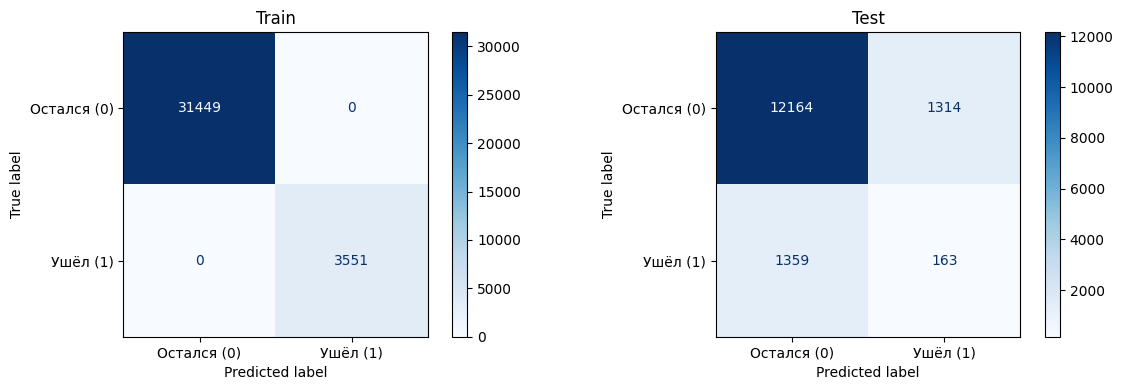

=== TRAIN ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     31449
           1       1.00      1.00      1.00      3551

    accuracy                           1.00     35000
   macro avg       1.00      1.00      1.00     35000
weighted avg       1.00      1.00      1.00     35000

=== TEST ===
              precision    recall  f1-score   support

           0       0.90      0.90      0.90     13478
           1       0.11      0.11      0.11      1522

    accuracy                           0.82     15000
   macro avg       0.50      0.50      0.50     15000
weighted avg       0.82      0.82      0.82     15000



In [8]:
#9 Вычисление ошибок и матрицы рассогласования
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Берем лучшую модель
best_model = grid_search.best_estimator_

# Делаем предсказания
y_train_pred = best_model.predict(X_train)
y_test_pred = best_model.predict(X_test)

# Строим матрицы рассогласования (Train и Test)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, y_true, y_pred, title in zip(
    axes, [y_train, y_test], [y_train_pred, y_test_pred], ['Train', 'Test']
):
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=['Остался (0)', 'Ушёл (1)'])
    disp.plot(ax=ax, cmap='Blues')
    ax.set_title(title)

plt.tight_layout()
plt.show()

print("=== TRAIN ===")
print(classification_report(y_train, y_train_pred))
print("=== TEST ===")
print(classification_report(y_test, y_test_pred))


=== Logistic Regression (TEST) ===
              precision    recall  f1-score   support

           0       0.92      0.59      0.72     13478
           1       0.13      0.51      0.20      1522

    accuracy                           0.59     15000
   macro avg       0.52      0.55      0.46     15000
weighted avg       0.84      0.59      0.67     15000



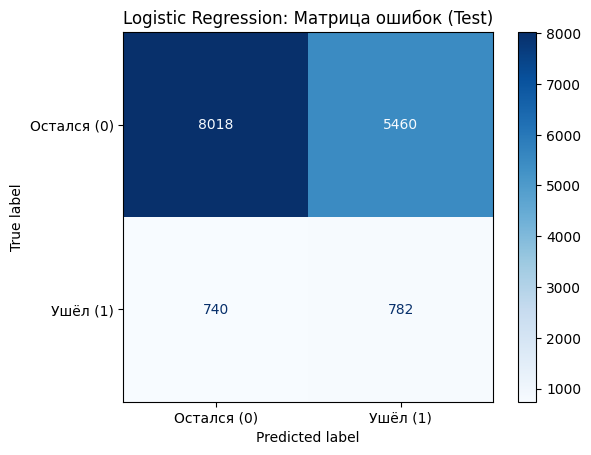

In [9]:
#10. Другой классификатор (Logistic Regression)
from sklearn.linear_model import LogisticRegression

# Создаем пайплайн
log_reg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])

# Обучение
log_reg_pipeline.fit(X_train, y_train)

# Предсказания
y_test_pred_lr = log_reg_pipeline.predict(X_test)

# Вывод метрик
print("=== Logistic Regression (TEST) ===")
print(classification_report(y_test, y_test_pred_lr))

# Матрица ошибок
cm_lr = confusion_matrix(y_test, y_test_pred_lr)
disp_lr = ConfusionMatrixDisplay(cm_lr, display_labels=['Остался (0)', 'Ушёл (1)'])
disp_lr.plot(cmap='Blues')
plt.title("Logistic Regression: Матрица ошибок (Test)")
plt.show()

## 13. Общие выводы

В ходе выполнения задания был проанализирован датасет **Intermediate Core ML Assignment Dataset**, предназначенный для прогнозирования оттока клиентов (churn). 

*   **Данные:** 50 000 объектов и 15 признаков (8 числовых, 7 категориальных). Целевая переменная `churn` имеет сильный дисбаланс: ~90% клиентов остаются и ~10% уходят.
*   **Предобработка:** Был построен пайплайн `Pipeline`, который автоматически обрабатывает пропуски (медиана для чисел, мода для категорий), кодирует категориальные признаки (`OneHotEncoder`) и нормализует числовые (`StandardScaler`). Выбросы в непрерывных числовых признаках были обрезаны по правилу IQR (только для train-выборки).
*   **Сравнение моделей:**
    *   В качестве базового классификатора был выбран **KNN** (метод ближайших соседей). С помощью `GridSearchCV` было подобрано оптимальное число соседей `k=1`. Однако модель показала сильное переобучение (Accuracy на train = 1.00). На тесте Accuracy составила 0.82, но **F1-мера для миноритарного класса (churn=1) оказалась крайне низкой (0.11)**. KNN пропускает 89% уходящих клиентов, так как «тонет» в большинстве класса 0.
    *   В качестве дополнительного метода была запущена **Logistic Regression** с параметром `class_weight='balanced'`. Она показала более низкую общую точность (Accuracy = 0.59), но **значительно лучший Recall (0.51) и F1 (0.20) для класса 1**. Модель находит 51% уходящих клиентов.
*   **Итоговый вывод:** Для задач с сильным дисбалансом классов (90/10) такие методы, как KNN, неэффективны, так как они не учитывают стоимость ошибки на миноритарном классе. Для реального бизнеса (где важно удерживать клиентов) предпочтительнее использовать алгоритмы с весами классов (Logistic Regression, Random Forest) или методы ресемплинга (SMOTE), пожертвовав частью общей точности ради нахождения уходящих клиентов.